# dropout_baseline

**Question.** How much does reconstruction degrade when probes drop out, and which methods stay robust when trained with dropout?

**Setup.** `configs/experiment/dropout_baseline.yaml`, Nektar u/v, N = 8 probes, seeds 0, 1, 2, 10 test draws per window. Faulty probes are flagged (oracle). Severity: each probe faulty with p (as in the meeting) and exactly k faulty probes. Record: `experiments/dropout_baseline/README.md`. Figures: `outputs/dropout_baseline/nektar_uv/figures/`.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from get_shredded import plots as gp
from get_shredded.runner import load_config, load_results, load_seed_info, output_root, run_name

cfg = load_config(["+experiment=dropout_baseline"])
ROOT = output_root(cfg)
RUNS = [run_name(r) for r in cfg.runs]
results = load_results(ROOT)
print(ROOT, f"{len(results)} run x seed results")

/Users/kaspervanderhorst/projects/shred/get-shredded/outputs/dropout_baseline/nektar_uv 24 run x seed results


In [2]:
def table(runs, conds):
    """Markdown table of mean ± std over seeds (relative L2 error) per run and condition."""
    rows = ["| Run | " + " | ".join(conds) + " |", "|---" + "|---:" * len(conds) + "|"]
    for m in gp.available_methods(results, runs):
        cells = [f"{mu:.4f} ± {sd:.4f}" for mu, sd, _ in (gp.metric_over_seeds(results, m, c) for c in conds)]
        rows.append(f"| {m} | " + " | ".join(cells) + " |")
    return Markdown("\n".join(rows))

## Probe layout

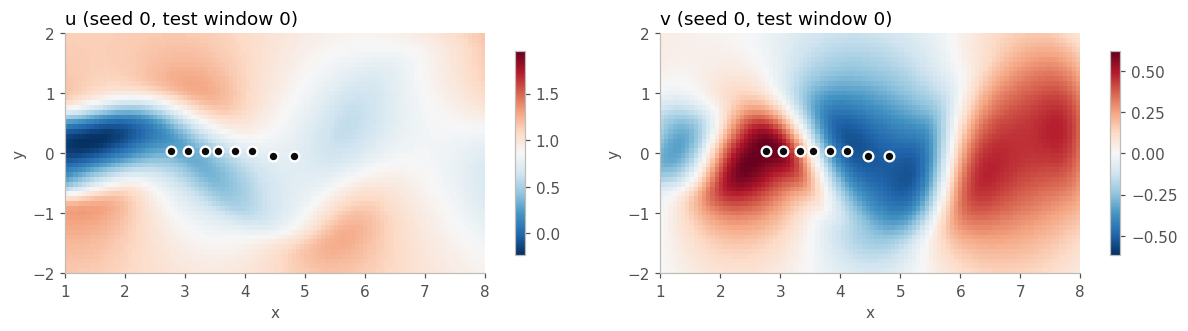

In [3]:
info = load_seed_info(ROOT, 0)
fig = gp.plot_sensor_layout(info, info["panel_truth"][0], "(seed 0, test window 0)")
gp.save(fig, ROOT, "probe_layout"); plt.show()

## Error at p = 0 and p = 0.3 (mean ± std over seeds)

In [4]:
display(table(RUNS, ["clean", "missing_oracle_p0", "missing_oracle_p0.3"]))
display(Markdown(gp.summary_table(results, RUNS)))

| Run | clean | missing_oracle_p0 | missing_oracle_p0.3 |
|---|---:|---:|---:|
| shred__noise | 0.0040 ± 0.0006 | 0.0047 ± 0.0006 | 0.1589 ± 0.0062 |
| shred__missing | 0.0102 ± 0.0027 | 0.0108 ± 0.0025 | 0.0145 ± 0.0035 |
| shred_mask__missing | 0.0099 ± 0.0013 | 0.0102 ± 0.0013 | 0.0113 ± 0.0018 |
| sdn__noise | 0.0040 ± 0.0004 | 0.0071 ± 0.0006 | 0.1803 ± 0.0061 |
| sdn__missing | 0.0101 ± 0.0012 | 0.0127 ± 0.0014 | 0.0243 ± 0.0017 |
| robust_shred_v1__missing | 0.0101 ± 0.0008 | 0.0110 ± 0.0008 | 0.0146 ± 0.0012 |
| robust_shred_v2__missing | 0.0098 ± 0.0007 | 0.0107 ± 0.0011 | 0.0143 ± 0.0016 |
| gappy_pod__clean | 0.0007 ± 0.0000 | 0.0139 ± 0.0003 | 0.0916 ± 0.0089 |

| Run | Params | Seeds | Clean | missing_oracle_p0 | missing_oracle_p0.3 | missing_oracle_p0.3 (u) | missing_oracle_p0.3 (v) |
|---|---:|---:|---:|---:|---:|---:|---:|
| shred__noise | 4,213,854 | 3 | 0.0040 ± 0.0006 | 0.0047 ± 0.0006 | 0.1589 ± 0.0062 | 0.0832 ± 0.0041 | 0.4734 ± 0.0174 |
| shred__missing | 4,213,854 | 3 | 0.0102 ± 0.0027 | 0.0108 ± 0.0025 | 0.0145 ± 0.0035 | 0.0076 ± 0.0018 | 0.0433 ± 0.0106 |
| shred_mask__missing | 4,215,390 | 3 | 0.0099 ± 0.0013 | 0.0102 ± 0.0013 | 0.0113 ± 0.0018 | 0.0059 ± 0.0009 | 0.0337 ± 0.0052 |
| sdn__noise | 4,156,350 | 3 | 0.0040 ± 0.0004 | 0.0071 ± 0.0006 | 0.1803 ± 0.0061 | 0.0928 ± 0.0040 | 0.5401 ± 0.0174 |
| sdn__missing | 4,156,350 | 3 | 0.0101 ± 0.0012 | 0.0127 ± 0.0014 | 0.0243 ± 0.0017 | 0.0125 ± 0.0008 | 0.0728 ± 0.0054 |
| robust_shred_v1__missing | 4,224,382 | 3 | 0.0101 ± 0.0008 | 0.0110 ± 0.0008 | 0.0146 ± 0.0012 | 0.0076 ± 0.0006 | 0.0436 ± 0.0035 |
| robust_shred_v2__missing | 4,273,086 | 3 | 0.0098 ± 0.0007 | 0.0107 ± 0.0011 | 0.0143 ± 0.0016 | 0.0074 ± 0.0008 | 0.0429 ± 0.0048 |
| gappy_pod__clean | – | 3 | 0.0007 ± 0.0000 | 0.0139 ± 0.0003 | 0.0916 ± 0.0089 | 0.0562 ± 0.0047 | 0.2551 ± 0.0269 |

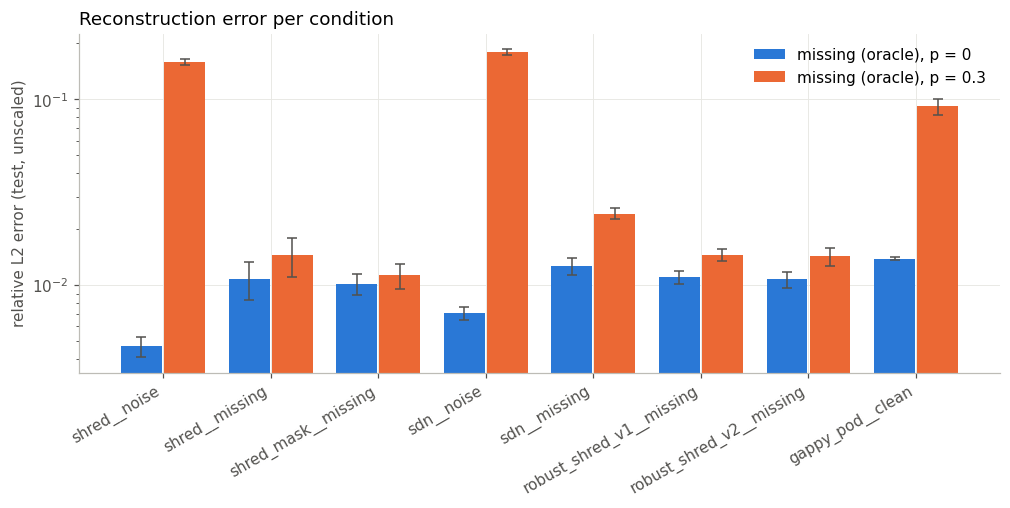

In [5]:
ax = gp.plot_error_bars(results, RUNS, ("missing_oracle_p0", "missing_oracle_p0.3"))
ax.set_yscale("log"); gp.save(ax.figure, ROOT, "error_bars"); plt.show()

## Error vs exactly k missing probes

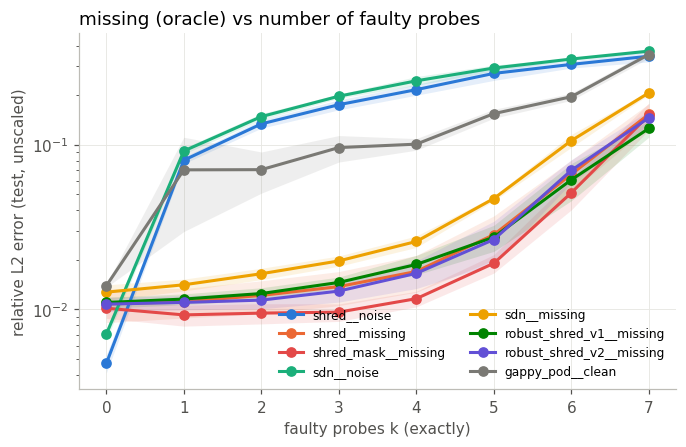

| Run | missing_oracle_k0 | missing_oracle_k1 | missing_oracle_k2 | missing_oracle_k3 | missing_oracle_k4 | missing_oracle_k5 | missing_oracle_k6 | missing_oracle_k7 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| shred__noise | 0.0047 ± 0.0006 | 0.0806 ± 0.0038 | 0.1340 ± 0.0078 | 0.1754 ± 0.0122 | 0.2165 ± 0.0162 | 0.2718 ± 0.0254 | 0.3083 ± 0.0153 | 0.3458 ± 0.0266 |
| shred__missing | 0.0108 ± 0.0025 | 0.0111 ± 0.0023 | 0.0121 ± 0.0028 | 0.0137 ± 0.0032 | 0.0170 ± 0.0043 | 0.0284 ± 0.0085 | 0.0662 ± 0.0144 | 0.1534 ± 0.0244 |
| shred_mask__missing | 0.0102 ± 0.0013 | 0.0092 ± 0.0013 | 0.0095 ± 0.0013 | 0.0096 ± 0.0012 | 0.0116 ± 0.0013 | 0.0190 ± 0.0024 | 0.0511 ± 0.0108 | 0.1512 ± 0.0282 |
| sdn__noise | 0.0071 ± 0.0006 | 0.0917 ± 0.0040 | 0.1484 ± 0.0063 | 0.1975 ± 0.0058 | 0.2450 ± 0.0149 | 0.2931 ± 0.0122 | 0.3324 ± 0.0050 | 0.3713 ± 0.0079 |
| sdn__missing | 0.0127 ± 0.0014 | 0.0141 ± 0.0012 | 0.0165 ± 0.0013 | 0.0197 ± 0.0014 | 0.0258 ± 0.0021 | 0.0471 ± 0.0015 | 0.1060 ± 0.0095 | 0.2071 ± 0.0053 |
| robust_shred_v1__missing | 0.0110 ± 0.0008 | 0.0115 ± 0.0009 | 0.0125 ± 0.0011 | 0.0146 ± 0.0011 | 0.0187 ± 0.0025 | 0.0274 ± 0.0050 | 0.0613 ± 0.0156 | 0.1258 ± 0.0145 |
| robust_shred_v2__missing | 0.0107 ± 0.0011 | 0.0110 ± 0.0011 | 0.0114 ± 0.0013 | 0.0129 ± 0.0018 | 0.0165 ± 0.0032 | 0.0266 ± 0.0077 | 0.0700 ± 0.0112 | 0.1459 ± 0.0153 |
| gappy_pod__clean | 0.0139 ± 0.0003 | 0.0704 ± 0.0407 | 0.0706 ± 0.0198 | 0.0962 ± 0.0176 | 0.1009 ± 0.0082 | 0.1547 ± 0.0096 | 0.1961 ± 0.0099 | 0.3541 ± 0.0169 |

In [6]:
ax = gp.plot_exact_k(results, RUNS, "missing_oracle", logy=True)
gp.save(ax.figure, ROOT, "error_exact_k"); plt.show()
display(table(RUNS, [f"missing_oracle_k{k}" for k in range(int(cfg.sensors.num))]))

## Reconstructions at p = 0.3 (seed 0, test window 0)

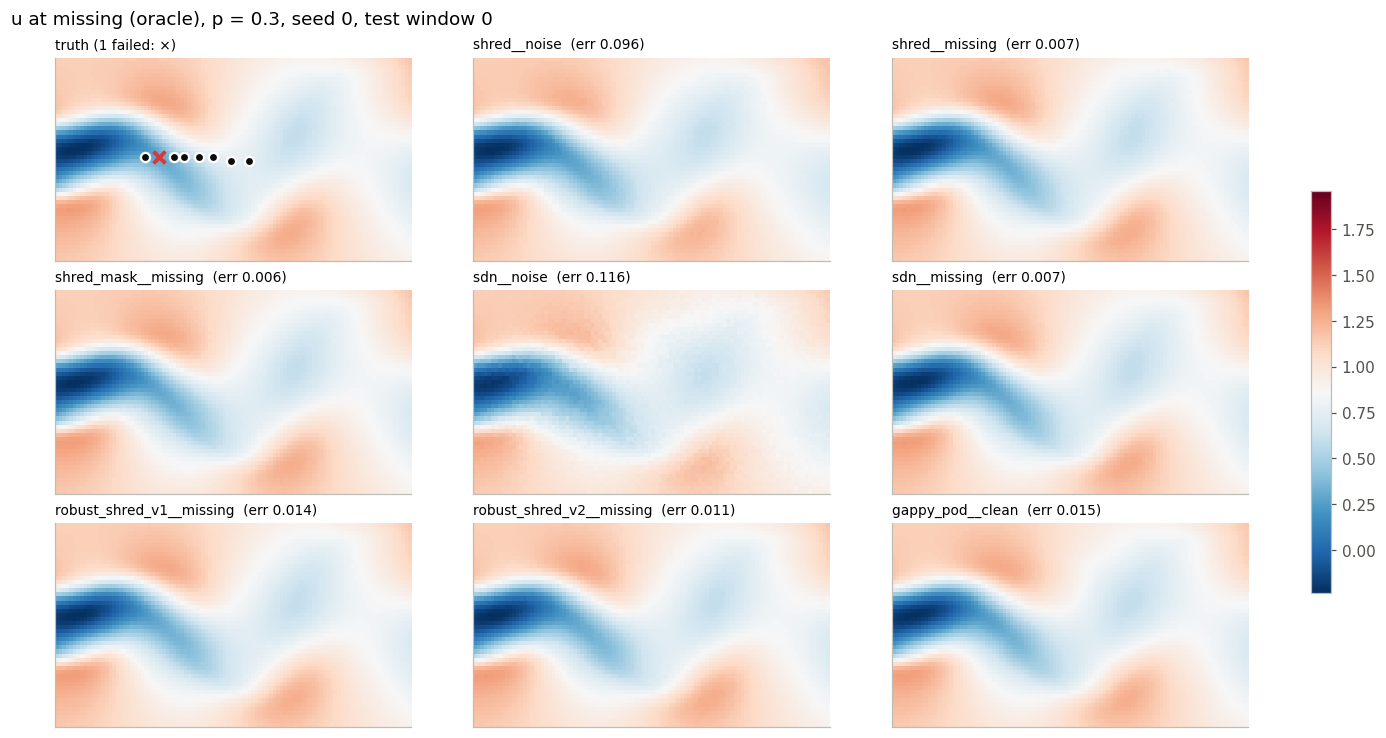

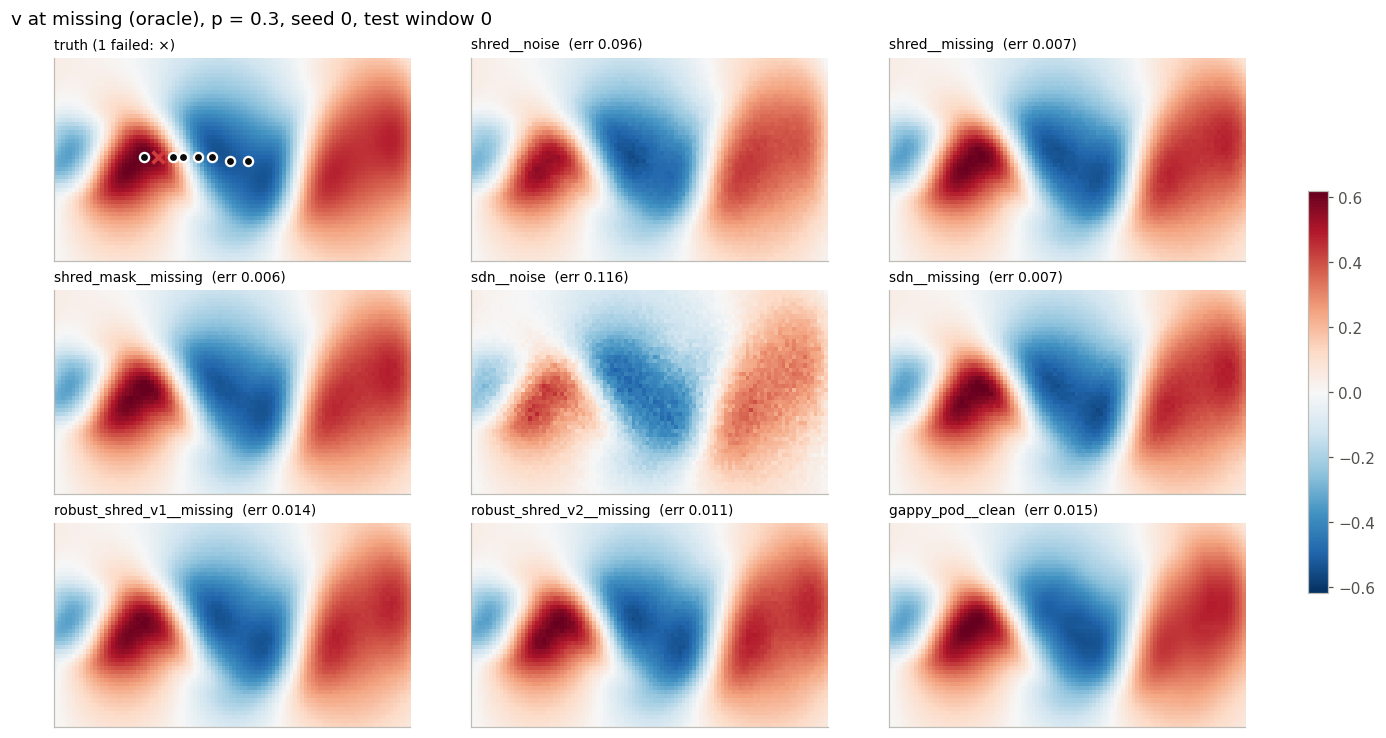

In [7]:
for ch in (0, 1):
    fig = gp.plot_reconstruction_panel(ROOT, results, RUNS, seed=0, cond="missing_oracle_p0.3", channel=ch)
    gp.save(fig, ROOT, f"panel_{'uv'[ch]}"); plt.show()